# Experiment 5: Social Network Analysis with R

## Aim

To implement Social Network Analysis by representing relationships between entities as a network of nodes and edges, analyzing important network characteristics, identifying influential nodes, and visualizing the resulting social network.

## Objectives

1. Prepare and import relationship data for social network analysis.
2. Represent entities as nodes (vertices).
3. Represent interactions as edges.
4. Construct a social network using R.
5. Visualize the network structure.
6. Calculate important network measures.
7. Identify highly connected and influential nodes.
8. Test and validate the implementation.
9. Interpret the obtained network structure and measures.

## Introduction

Social Network Analysis is a method used to study relationships and interactions among entities.

Unlike traditional datasets where each observation is generally treated independently, network analysis focuses on the **relationships between observations**.

A network consists of two major components:

- **Nodes (Vertices):** Represent entities such as people, organizations, websites, or devices.
- **Edges (Links):** Represent relationships or interactions between the entities.

For example, in a social network:

- A person represents a node.
- A friendship or interaction represents an edge.

In this experiment, a small social interaction dataset is created and analyzed using the `igraph` package in R.

In [18]:
system(
  "apt-get update -qq && apt-get install -y r-cran-igraph",
  intern = FALSE
)

In [32]:
library(igraph)
cat("igraph loaded successfully!\n")
cat("igraph version:", as.character(packageVersion("igraph")), "\n")

igraph loaded successfully!
igraph version: 2.3.3 


## Step 1: Preparing the Network Dataset

Sample social interaction dataset is created.

Each row represents a relationship between two individuals:

- `from` = source/person initiating the relationship
- `to` = person connected to the source

The dataset can represent interactions such as friendships, communication, collaboration, or social connections.

The data is represented in **edge-list format**, which is one of the common formats used for network analysis.

In [6]:
# Create sample social network data

social_data <- data.frame(
  from = c(
    "Alice", "Alice", "Alice",
    "Bob", "Bob",
    "Charlie", "Charlie",
    "David", "David",
    "Eve",
    "Frank", "Frank",
    "Grace",
    "Henry"
  ),

  to = c(
    "Bob", "Charlie", "David",
    "Charlie", "Eve",
    "David", "Frank",
    "Eve", "Grace",
    "Frank",
    "Grace", "Henry",
    "Henry", "Alice"
  )
)

# Display the dataset
social_data

from,to
<chr>,<chr>
Alice,Bob
Alice,Charlie
Alice,David
Bob,Charlie
Bob,Eve
Charlie,David
Charlie,Frank
David,Eve
David,Grace


## Step 2: Understanding the Dataset

The dataset is stored as an **edge list**.

For example, if the dataset contains:

`Alice → Bob`

it means that an interaction or relationship exists between Alice and Bob.

The edge-list representation makes it easy to construct a graph because every row directly describes a connection between two nodes.

In [7]:
library(igraph)

cat("====================================\n")
cat("igraph loaded successfully!\n")
cat("igraph version:", as.character(packageVersion("igraph")), "\n")
cat("====================================\n")

,from,to
,<chr>,<chr>
1,Alice,Bob
2,Alice,Charlie
3,Alice,David
4,Bob,Charlie
5,Bob,Eve
6,Charlie,David


Number of relationships: 14 
Number of unique individuals: 8 

Individuals in the network:
[1] "Alice"   "Bob"     "Charlie" "David"   "Eve"     "Frank"   "Grace"  
[8] "Henry"  


## Step 3: Constructing the Social Network

The `igraph` package provides functions for creating and analyzing graphs.

The `graph_from_data_frame()` function converts the edge-list dataset into an `igraph` network.

In this experiment:

- Vertices represent individuals.
- Edges represent social interactions.
- The graph is treated as **undirected**, meaning that a relationship between two people is considered mutual.

The resulting graph can then be analyzed using different network-analysis functions.

In [20]:
# Create an undirected social network

social_graph <- graph_from_data_frame(
  social_data,
  directed = FALSE
)

# Display graph information
social_graph

# Display vertices
V(social_graph)

# Display edges
E(social_graph)

IGRAPH 0760469 UN-- 8 14 -- 
+ attr: name (v/c)
+ edges from 0760469 (vertex names):
 [1] Alice  --Bob     Alice  --Charlie Alice  --David   Bob    --Charlie
 [5] Bob    --Eve     Charlie--David   Charlie--Frank   David  --Eve    
 [9] David  --Grace   Eve    --Frank   Frank  --Grace   Frank  --Henry  
[13] Grace  --Henry   Alice  --Henry  

+ 8/8 vertices, named, from 0760469:
[1] Alice   Bob     Charlie David   Eve     Frank   Grace   Henry  

+ 14/14 edges from 0760469 (vertex names):
 [1] Alice  --Bob     Alice  --Charlie Alice  --David   Bob    --Charlie
 [5] Bob    --Eve     Charlie--David   Charlie--Frank   David  --Eve    
 [9] David  --Grace   Eve    --Frank   Frank  --Grace   Frank  --Henry  
[13] Grace  --Henry   Alice  --Henry  

## Step 4: Basic Network Characteristics

Before visualizing the network, we calculate some basic characteristics.

Important characteristics include:

- **Number of nodes:** Total entities present in the network.
- **Number of edges:** Total relationships between entities.
- **Network density:** Indicates how many of the possible connections actually exist.

A higher density indicates that a larger proportion of possible relationships are present in the network.

In [21]:
# Number of nodes
num_nodes <- vcount(social_graph)

# Number of edges
num_edges <- ecount(social_graph)

# Network density
network_density <- edge_density(social_graph)

cat("===== BASIC NETWORK STATISTICS =====\n")
cat("Number of Nodes :", num_nodes, "\n")
cat("Number of Edges :", num_edges, "\n")
cat("Network Density :", round(network_density, 4), "\n")

===== BASIC NETWORK STATISTICS =====
Number of Nodes : 8 
Number of Edges : 14 
Network Density : 0.5 


## Step 5: Calculating Node Degree

**Degree centrality** measures the number of direct connections that a node has.

A node with a high degree:

- Has many direct relationships.
- Is highly connected to other nodes.
- May have greater interaction within the network.

Therefore, degree is useful for identifying highly connected individuals.

In [22]:
# Calculate degree of every node

degree_values <- degree(
  social_graph,
  mode = "all"
)

degree_table <- data.frame(
  Node = names(degree_values),
  Degree = as.numeric(degree_values)
)

# Sort nodes according to degree
degree_table <- degree_table[
  order(-degree_table$Degree),
]

rownames(degree_table) <- NULL

degree_table

Node,Degree
<chr>,<dbl>
Alice,4
Charlie,4
David,4
Frank,4
Bob,3
Eve,3
Grace,3
Henry,3


## Interpretation of Degree

The nodes with the largest degree values have the highest number of direct connections.

Such nodes can be considered **highly connected individuals** in the social network.

However, having many direct connections does not necessarily mean that a node connects different parts of the network. For that reason, additional centrality measures such as betweenness and closeness are also calculated.

## Step 6: Betweenness Centrality

**Betweenness centrality** measures how frequently a node lies on the shortest paths between other nodes.

A node with high betweenness can act as a:

- Bridge between groups.
- Connector between different parts of the network.
- Important intermediary in information flow.

Therefore, betweenness is useful for identifying nodes that connect otherwise less-connected individuals.

In [23]:
# Calculate betweenness centrality

betweenness_values <- betweenness(
  social_graph,
  directed = FALSE,
  normalized = TRUE
)

betweenness_table <- data.frame(
  Node = names(betweenness_values),
  Betweenness = round(
    as.numeric(betweenness_values),
    4
  )
)

# Sort by betweenness
betweenness_table <- betweenness_table[
  order(-betweenness_table$Betweenness),
]

rownames(betweenness_table) <- NULL

betweenness_table

Node,Betweenness
<chr>,<dbl>
Frank,0.1508
David,0.1349
Alice,0.1270
Charlie,0.0952
Eve,0.0714
Henry,0.0556
Bob,0.0397
Grace,0.0397


## Step 7: Closeness Centrality

**Closeness centrality** measures how close a node is to all other nodes based on the shortest paths in the network.

A node with high closeness can potentially reach other nodes through relatively short paths.

This measure helps identify nodes that are centrally positioned within the network.

In [24]:
# Calculate closeness centrality

closeness_values <- closeness(
  social_graph,
  normalized = TRUE
)

closeness_table <- data.frame(
  Node = names(closeness_values),
  Closeness = round(
    as.numeric(closeness_values),
    4
  )
)

# Sort by closeness
closeness_table <- closeness_table[
  order(-closeness_table$Closeness),
]

rownames(closeness_table) <- NULL

closeness_table

Node,Closeness
<chr>,<dbl>
Alice,0.7000
Charlie,0.7000
David,0.7000
Frank,0.7000
Eve,0.6364
Henry,0.6364
Bob,0.5833
Grace,0.5833


## Step 8: Combining Network Measures

To compare individuals more effectively, the calculated centrality measures are combined into a single table.

The table contains:

- Degree
- Betweenness centrality
- Closeness centrality

This allows us to examine the importance of each node from multiple perspectives rather than relying on only one measure.

In [25]:
# Calculate all centrality measures

degree_values <- degree(social_graph)
betweenness_values <- betweenness(
  social_graph,
  directed = FALSE,
  normalized = TRUE
)
closeness_values <- closeness(
  social_graph,
  normalized = TRUE
)

# Create combined table

centrality_table <- data.frame(
  Node = V(social_graph)$name,
  Degree = as.numeric(degree_values),
  Betweenness = round(
    as.numeric(betweenness_values),
    4
  ),
  Closeness = round(
    as.numeric(closeness_values),
    4
  )
)

# Sort by degree
centrality_table <- centrality_table[
  order(-centrality_table$Degree),
]

rownames(centrality_table) <- NULL

centrality_table

Node,Degree,Betweenness,Closeness
<chr>,<dbl>,<dbl>,<dbl>
Alice,4,0.1270,0.7000
Charlie,4,0.0952,0.7000
David,4,0.1349,0.7000
Frank,4,0.1508,0.7000
Bob,3,0.0397,0.5833
Eve,3,0.0714,0.6364
Grace,3,0.0397,0.5833
Henry,3,0.0556,0.6364


## Step 9: Identifying Important Nodes

The node with the highest degree is identified as the most directly connected node.

The node with the highest betweenness is identified as an important intermediary or bridge.

The node with the highest closeness is considered centrally positioned with respect to the other nodes.

Therefore, different centrality measures can identify different types of influential nodes.

In [26]:
# Identify important nodes

highest_degree_node <- centrality_table$Node[
  which.max(centrality_table$Degree)
]

highest_betweenness_node <- centrality_table$Node[
  which.max(centrality_table$Betweenness)
]

highest_closeness_node <- centrality_table$Node[
  which.max(centrality_table$Closeness)
]

cat("===== IMPORTANT NODES =====\n")

cat(
  "Highest Degree Node      :",
  highest_degree_node,
  "\n"
)

cat(
  "Highest Betweenness Node :",
  highest_betweenness_node,
  "\n"
)

cat(
  "Highest Closeness Node   :",
  highest_closeness_node,
  "\n"
)

===== IMPORTANT NODES =====
Highest Degree Node      : Alice 
Highest Betweenness Node : Frank 
Highest Closeness Node   : Alice 


## Step 10: Visualizing the Social Network

Visualization is an important component of Social Network Analysis because it provides a graphical representation of the relationships.

In the network visualization:

- Each circle represents an individual.
- Each line represents a relationship.
- Node size represents the degree of the node.
- Node labels identify the individuals.
- The layout determines the spatial arrangement of the network.

Larger nodes therefore indicate individuals with more direct connections.

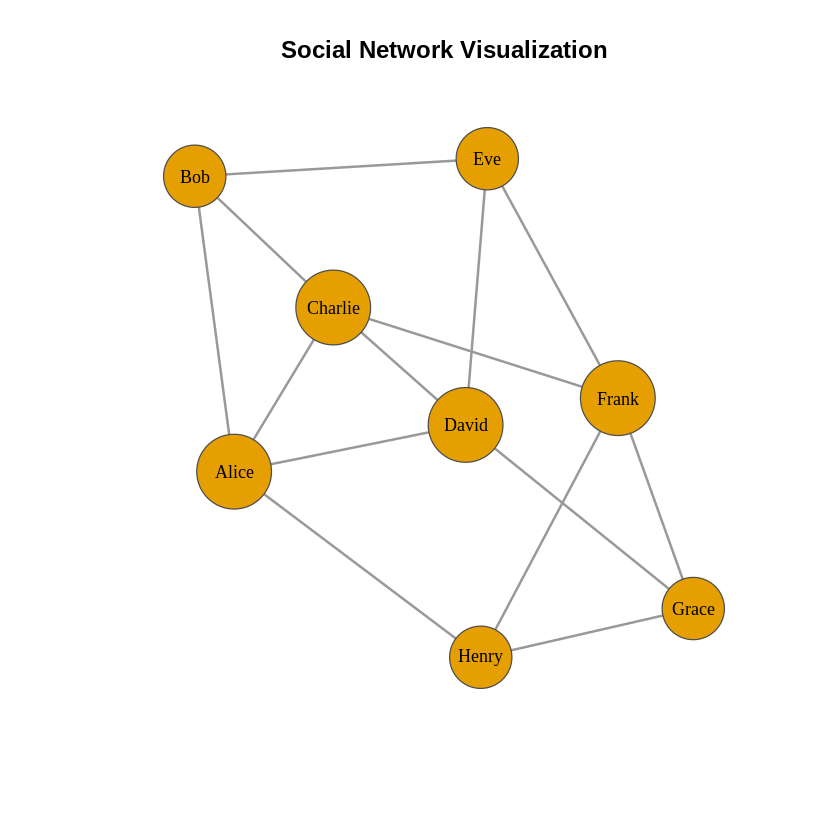

In [27]:
# Set node size based on degree
V(social_graph)$size <- 10 + degree(social_graph) * 5

# Set node labels
V(social_graph)$label <- V(social_graph)$name

# Set edge width
E(social_graph)$width <- 2

# Generate network visualization

set.seed(123)

plot(
  social_graph,
  layout = layout_with_fr(social_graph),
  vertex.label.cex = 0.9,
  vertex.label.color = "black",
  vertex.frame.color = "gray30",
  edge.color = "gray60",
  main = "Social Network Visualization"
)

## Step 11: Highlighting the Most Connected Node

To make the analysis easier to interpret, the node with the highest degree can be visually highlighted.

This helps us quickly identify the individual with the greatest number of direct connections.

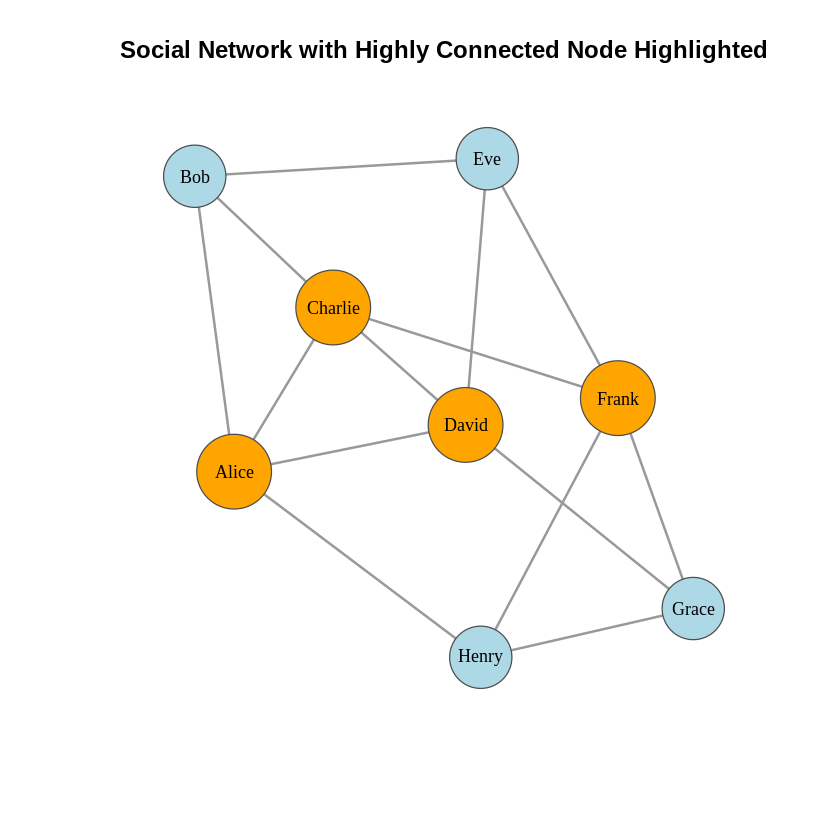

In [28]:
# Identify node with maximum degree
max_degree <- max(degree(social_graph))

# Assign default node color
V(social_graph)$color <- "lightblue"

# Highlight node(s) with highest degree
V(social_graph)$color[
  degree(social_graph) == max_degree
] <- "orange"

# Plot highlighted network

set.seed(123)

plot(
  social_graph,
  layout = layout_with_fr(social_graph),
  vertex.size = 10 + degree(social_graph) * 5,
  vertex.label.cex = 0.9,
  vertex.label.color = "black",
  vertex.frame.color = "gray30",
  edge.width = 2,
  edge.color = "gray60",
  main = "Social Network with Highly Connected Node Highlighted"
)

## Step 12: Network-Level Analysis

The network can also be analyzed using additional structural characteristics.

Important characteristics include:

- Average degree
- Number of connected components
- Average path length
- Network diameter

These measures provide a broader understanding of how the network is organized.

In [29]:
# Calculate additional network characteristics

average_degree <- mean(degree(social_graph))

components_info <- components(social_graph)

number_components <- components_info$no

average_path <- mean_distance(
  social_graph,
  directed = FALSE
)

network_diameter <- diameter(
  social_graph,
  directed = FALSE
)

cat("===== NETWORK STRUCTURE =====\n")
cat(
  "Average Degree       :",
  round(average_degree, 2),
  "\n"
)

cat(
  "Connected Components :",
  number_components,
  "\n"
)

cat(
  "Average Path Length  :",
  round(average_path, 3),
  "\n"
)

cat(
  "Network Diameter     :",
  network_diameter,
  "\n"
)

===== NETWORK STRUCTURE =====
Average Degree       : 3.5 
Connected Components : 1 
Average Path Length  : 1.536 
Network Diameter     : 3 


## Step 13: Testing the Implementation

The implementation should be tested to ensure that the constructed graph correctly represents the original relationship data.

We verify:

1. The number of graph nodes matches the number of unique individuals.
2. The number of graph edges matches the number of relationships.
3. Every edge connects valid nodes.
4. Centrality measures are successfully calculated.
5. The graph contains at least one node and one edge.

These checks help validate that the network has been constructed correctly.

In [30]:
# Test 1: Number of nodes
test_nodes <- vcount(social_graph) == length(nodes)

# Test 2: Number of edges
test_edges <- ecount(social_graph) == nrow(social_data)

# Test 3: Graph contains nodes
test_vertices <- vcount(social_graph) > 0

# Test 4: Graph contains edges
test_links <- ecount(social_graph) > 0

# Test 5: Centrality values calculated
test_centrality <- (
  length(degree_values) == vcount(social_graph)
)

cat("===== VALIDATION RESULTS =====\n")

cat(
  "Node count test       :",
  ifelse(test_nodes, "PASS", "FAIL"),
  "\n"
)

cat(
  "Edge count test       :",
  ifelse(test_edges, "PASS", "FAIL"),
  "\n"
)

cat(
  "Vertices existence    :",
  ifelse(test_vertices, "PASS", "FAIL"),
  "\n"
)

cat(
  "Edges existence       :",
  ifelse(test_links, "PASS", "FAIL"),
  "\n"
)

cat(
  "Centrality calculation:",
  ifelse(test_centrality, "PASS", "FAIL"),
  "\n"
)

===== VALIDATION RESULTS =====
Node count test       : PASS 
Edge count test       : PASS 
Vertices existence    : PASS 
Edges existence       : PASS 
Centrality calculation: PASS 


## Step 14: Final Results

The following output summarizes the main findings of the Social Network Analysis.

The analysis provides:

- Total number of individuals.
- Total number of relationships.
- Network density.
- Average node degree.
- Important nodes according to different centrality measures.
- Overall network structure.

In [31]:
# Create final summary

final_summary <- data.frame(
  Measure = c(
    "Number of Nodes",
    "Number of Edges",
    "Network Density",
    "Average Degree",
    "Connected Components",
    "Average Path Length",
    "Network Diameter",
    "Highest Degree Node",
    "Highest Betweenness Node",
    "Highest Closeness Node"
  ),

  Result = c(
    num_nodes,
    num_edges,
    round(network_density, 4),
    round(average_degree, 2),
    number_components,
    round(average_path, 3),
    network_diameter,
    highest_degree_node,
    highest_betweenness_node,
    highest_closeness_node
  )
)

final_summary

Measure,Result
<chr>,<chr>
Number of Nodes,8
Number of Edges,14
Network Density,0.5
Average Degree,3.5
Connected Components,1
Average Path Length,1.536
Network Diameter,3
Highest Degree Node,Alice
Highest Betweenness Node,Frank


## Conclusion

The Social Network Analysis experiment was successfully implemented using R and the `igraph` package.

The relationship data was represented using an edge-list structure and converted into a graph containing nodes and edges. Network visualization was generated to understand the relationship structure.

Important network measures including degree centrality, betweenness centrality, and closeness centrality were calculated. These measures were used to identify highly connected, intermediary, and centrally positioned nodes.

The implementation was also validated using basic tests to ensure that the number of nodes and edges corresponded to the original dataset and that the centrality calculations were successfully performed.

Overall, the experiment demonstrates how R Programming can be used to construct, analyze, visualize, and interpret social networks.